# Which Factors Matter? Domain-Level Ablation and Explainable Analysis of Student Stress Prediction

In [1]:
# Step 1: Setup, data audit and domain mapping
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

SEED = 42
TARGET = "stress_level"

df = pd.read_csv("StressLevelDataset.csv")

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nClass counts:")
print(df[TARGET].value_counts().sort_index())

DOMAINS = {
    "Psychological": ["anxiety_level", "self_esteem", "mental_health_history", "depression"],
    "Physiological": ["headache", "blood_pressure", "sleep_quality", "breathing_problem"],
    "Environmental": ["noise_level", "living_conditions", "safety", "basic_needs"],
    "Academic": ["academic_performance", "study_load", "teacher_student_relationship", "future_career_concerns"],
    "Social": ["social_support", "peer_pressure", "extracurricular_activities", "bullying"],
}

FEATURES = [f for fs in DOMAINS.values() for f in fs]
assert set(FEATURES) == set(df.columns) - {TARGET}, "Feature mismatch"

X = df[FEATURES]
y = df[TARGET]
print("\nFeatures:", len(FEATURES), "| Domains:", len(DOMAINS))

Shape: (1100, 21)
Missing values: 0
Duplicate rows: 0

Class counts:
stress_level
0    373
1    358
2    369
Name: count, dtype: int64

Features: 20 | Domains: 5


In [2]:
# Step 2: Stratified split and CV setup
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.metrics import make_scorer, matthews_corrcoef

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Train:", X_train.shape, "| Holdout:", X_test.shape)

N_SPLITS, N_REPEATS = 5, 3
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

SCORING = {
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro",
    "balanced_acc": "balanced_accuracy",
    "mcc": make_scorer(matthews_corrcoef),
}

Train: (880, 20) | Holdout: (220, 20)


In [3]:
# Step 3: Baseline models (preprocessing inside Pipeline)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_validate

def build_pipe(name):
    models = {
        "LogReg": LogisticRegression(max_iter=2000, random_state=SEED),
        "RandomForest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
        "GradBoost": GradientBoostingClassifier(random_state=SEED),
    }
    return Pipeline([("scaler", StandardScaler()), ("clf", models[name])])

rows = []
for name in ["LogReg", "RandomForest", "GradBoost"]:
    res = cross_validate(build_pipe(name), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    row = {"model": name}
    for m in SCORING:
        row[m] = res["test_" + m].mean()
        row[m + "_sd"] = res["test_" + m].std()
    rows.append(row)

baseline = pd.DataFrame(rows).set_index("model")
print(baseline[list(SCORING)].round(4))

BEST_MODEL = baseline["f1_weighted"].idxmax()
print("\nSelected model:", BEST_MODEL)

              f1_weighted  f1_macro  balanced_acc     mcc
model                                                    
LogReg             0.8799    0.8800        0.8798  0.8211
RandomForest       0.8699    0.8699        0.8700  0.8066
GradBoost          0.8791    0.8790        0.8791  0.8198

Selected model: LogReg


In [4]:
# Step 4: Domain ablation (drop-one and only-one) with tuning inside each fold
from sklearn.model_selection import GridSearchCV, StratifiedKFold

GRIDS = {
    "LogReg": {"clf__C": [0.1, 1, 10]},
    "RandomForest": {"clf__max_depth": [None, 8], "clf__min_samples_leaf": [1, 3]},
    "GradBoost": {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]},
}

def tuned_model(name, seed=SEED):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    return GridSearchCV(build_pipe(name), GRIDS[name], cv=inner, scoring="f1_weighted", n_jobs=-1)

def run_condition(cols):
    res = cross_validate(tuned_model(BEST_MODEL), X_train[cols], y_train, cv=cv, scoring=SCORING, n_jobs=1)
    return {m: res["test_" + m] for m in SCORING}

conditions = {"All features": FEATURES}
for d, fs in DOMAINS.items():
    conditions["Drop " + d] = [f for f in FEATURES if f not in fs]
for d, fs in DOMAINS.items():
    conditions["Only " + d] = fs

fold_scores = {}
for label, cols in conditions.items():
    fold_scores[label] = run_condition(cols)
    print(f"{label:<24} F1w = {fold_scores[label]['f1_weighted'].mean():.4f}")

ablation = pd.DataFrame({
    label: {m: s[m].mean() for m in SCORING} for label, s in fold_scores.items()
}).T
ablation["n_features"] = [len(c) for c in conditions.values()]
print()
print(ablation.round(4))

All features             F1w = 0.8784
Drop Psychological       F1w = 0.8769
Drop Physiological       F1w = 0.8690
Drop Environmental       F1w = 0.8850
Drop Academic            F1w = 0.8862
Drop Social              F1w = 0.8823
Only Psychological       F1w = 0.8771
Only Physiological       F1w = 0.8840
Only Environmental       F1w = 0.8742
Only Academic            F1w = 0.8686
Only Social              F1w = 0.8661

                    f1_weighted  f1_macro  balanced_acc     mcc  n_features
All features             0.8784    0.8785        0.8783  0.8189          20
Drop Psychological       0.8769    0.8770        0.8768  0.8165          16
Drop Physiological       0.8690    0.8689        0.8690  0.8046          16
Drop Environmental       0.8850    0.8851        0.8848  0.8285          16
Drop Academic            0.8862    0.8863        0.8859  0.8300          16
Drop Social              0.8823    0.8824        0.8819  0.8252          16
Only Psychological       0.8771    0.8770        

In [5]:
# Step 5: Paired tests and bootstrap confidence intervals
from scipy.stats import wilcoxon

rng = np.random.default_rng(SEED)
base = fold_scores["All features"]["f1_weighted"]
rows = []
for d in DOMAINS:
    other = fold_scores["Drop " + d]["f1_weighted"]
    diff = base - other
    stat, p = wilcoxon(base, other)
    boot = [rng.choice(diff, size=len(diff), replace=True).mean() for _ in range(5000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows.append({"domain": d, "mean_drop": diff.mean(), "ci_low": lo, "ci_high": hi, "p_value": p})

stats_df = pd.DataFrame(rows).set_index("domain")
order = stats_df["p_value"].sort_values().index
m = len(order)
adj = {}
running = 0
for i, d in enumerate(order):
    running = max(running, min(1, stats_df.loc[d, "p_value"] * (m - i)))
    adj[d] = running
stats_df["p_holm"] = pd.Series(adj)
print(stats_df.round(4))

               mean_drop  ci_low  ci_high  p_value  p_holm
domain                                                    
Psychological     0.0015 -0.0039   0.0056   0.1688  0.3376
Physiological     0.0094  0.0034   0.0155   0.0181  0.0723
Environmental    -0.0066 -0.0112  -0.0020   0.0186  0.0723
Academic         -0.0078 -0.0130  -0.0029   0.0067  0.0336
Social           -0.0039 -0.0092   0.0017   0.1876  0.3376


In [6]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


Best params: {'clf__C': 1}
Holdout weighted F1: 0.8817
Holdout balanced acc: 0.8821
Holdout MCC: 0.8227
SHAP shape: (220, 20, 3)
blood_pressure                  1.7183
social_support                  0.8335
self_esteem                     0.2569
academic_performance            0.2264
study_load                      0.2076
mental_health_history           0.2056
teacher_student_relationship    0.2018
basic_needs                     0.1879
headache                        0.1876
sleep_quality                   0.1315
dtype: float64


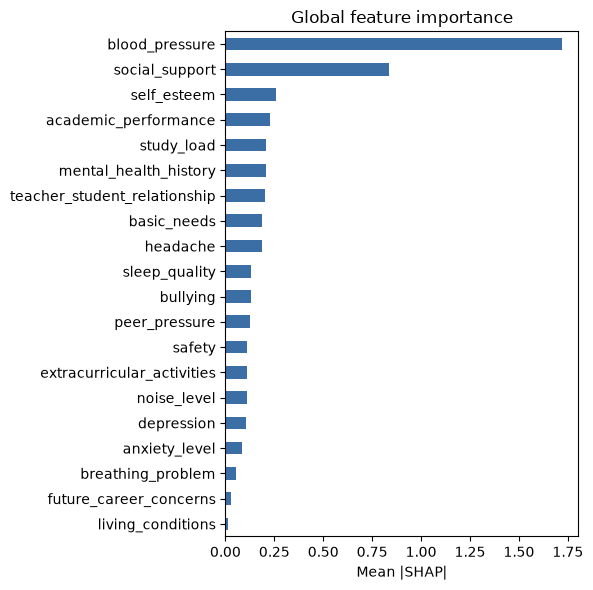

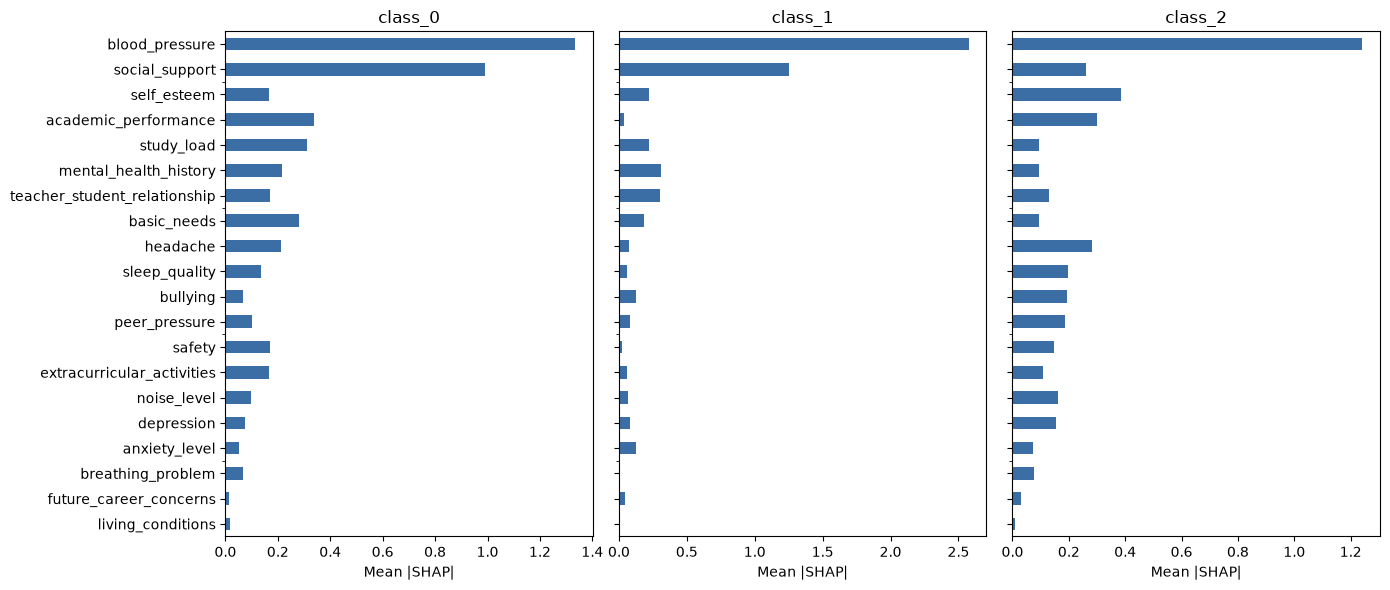

In [7]:
# Step 6: SHAP global and class-wise importance
import shap

final_model = tuned_model(BEST_MODEL).fit(X_train, y_train)
best_pipe = final_model.best_estimator_
print("Best params:", final_model.best_params_)

from sklearn.metrics import f1_score, balanced_accuracy_score
pred = final_model.predict(X_test)
print("Holdout weighted F1:", round(f1_score(y_test, pred, average="weighted"), 4))
print("Holdout balanced acc:", round(balanced_accuracy_score(y_test, pred), 4))
print("Holdout MCC:", round(matthews_corrcoef(y_test, pred), 4))

scaler = best_pipe.named_steps["scaler"]
clf = best_pipe.named_steps["clf"]
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)

if BEST_MODEL == "LogReg":
    explainer = shap.LinearExplainer(clf, shap.maskers.Independent(X_train_s, max_samples=len(X_train_s)))
    sv = explainer.shap_values(X_test_s)
else:
    explainer = shap.TreeExplainer(clf)
    sv = explainer.shap_values(X_test_s)

sv = np.array(sv)
if sv.shape[0] == 3 and sv.shape[1] == len(X_test_s):
    sv = np.transpose(sv, (1, 2, 0))
print("SHAP shape:", sv.shape)

class_imp = np.abs(sv).mean(axis=0)
class_imp_df = pd.DataFrame(class_imp, index=FEATURES, columns=[f"class_{c}" for c in clf.classes_])
global_imp = pd.Series(class_imp.mean(axis=1), index=FEATURES).sort_values(ascending=False)
print(global_imp.round(4).head(10))

global_imp.sort_values().plot.barh(figsize=(6, 6), color="#3b6ea5")
plt.xlabel("Mean |SHAP|")
plt.title("Global feature importance")
plt.tight_layout()
plt.savefig("shap_global.png", dpi=200)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 6), sharey=True)
order_f = global_imp.sort_values().index
for i, c in enumerate(class_imp_df.columns):
    class_imp_df.loc[order_f, c].plot.barh(ax=axes[i], color="#3b6ea5")
    axes[i].set_title(c)
    axes[i].set_xlabel("Mean |SHAP|")
plt.tight_layout()
plt.savefig("shap_classwise.png", dpi=200)
plt.show()

               shap_importance  drop_one_loss  only_one_f1  shap_rank  \
Academic                0.6665        -0.0078       0.8686        3.0   
Environmental           0.4197        -0.0066       0.8742        5.0   
Physiological           2.0892         0.0094       0.8840        1.0   
Psychological           0.6489         0.0015       0.8771        4.0   
Social                  1.1976        -0.0039       0.8661        2.0   

               drop_rank  only_rank  
Academic             5.0        4.0  
Environmental        4.0        3.0  
Physiological        1.0        1.0  
Psychological        2.0        2.0  
Social               3.0        5.0  

SHAP vs drop-one : rho = 0.500, p = 0.391
SHAP vs only-one : rho = 0.100, p = 0.873


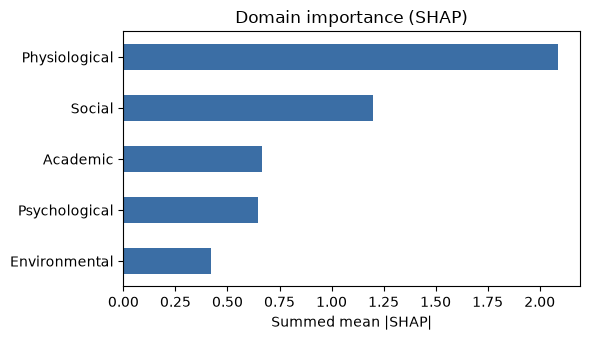

In [8]:
# Step 7: SHAP domain ranking vs ablation ranking (Spearman)
from scipy.stats import spearmanr

feat_to_domain = {f: d for d, fs in DOMAINS.items() for f in fs}
shap_domain = global_imp.groupby(feat_to_domain).sum()

comparison = pd.DataFrame({
    "shap_importance": shap_domain,
    "drop_one_loss": stats_df["mean_drop"],
    "only_one_f1": pd.Series({d: fold_scores["Only " + d]["f1_weighted"].mean() for d in DOMAINS}),
})
comparison["shap_rank"] = comparison["shap_importance"].rank(ascending=False)
comparison["drop_rank"] = comparison["drop_one_loss"].rank(ascending=False)
comparison["only_rank"] = comparison["only_one_f1"].rank(ascending=False)
print(comparison.round(4))

rho_drop, p_drop = spearmanr(comparison["shap_importance"], comparison["drop_one_loss"])
rho_only, p_only = spearmanr(comparison["shap_importance"], comparison["only_one_f1"])
print(f"\nSHAP vs drop-one : rho = {rho_drop:.3f}, p = {p_drop:.3f}")
print(f"SHAP vs only-one : rho = {rho_only:.3f}, p = {p_only:.3f}")

comparison[["shap_importance"]].sort_values("shap_importance").plot.barh(figsize=(6, 3.5), legend=False, color="#3b6ea5")
plt.xlabel("Summed mean |SHAP|")
plt.title("Domain importance (SHAP)")
plt.tight_layout()
plt.savefig("domain_shap.png", dpi=200)
plt.show()

               change  mean_prob_before  mean_prob_after  mean_change
feature                                                              
sleep_quality      +1            0.3292           0.3236      -0.0056
social_support     +1            0.3292           0.3324       0.0031
study_load         -1            0.3292           0.3255      -0.0037
noise_level        -1            0.3292           0.3232      -0.0061
peer_pressure      -1            0.3292           0.3229      -0.0064
bullying           -1            0.3292           0.3232      -0.0060


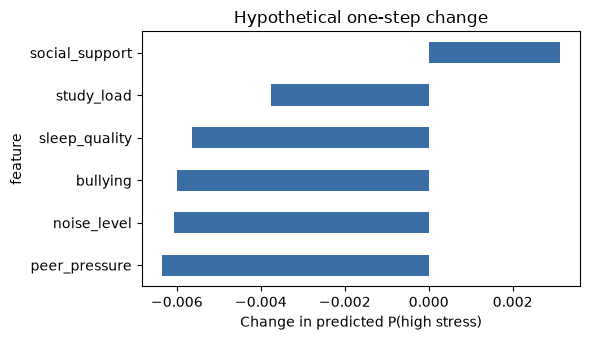

In [9]:
# Step 8: Small what-if analysis on modifiable features
HIGH_CLASS = list(clf.classes_).index(2)

WHAT_IF = {
    "sleep_quality": +1,
    "social_support": +1,
    "study_load": -1,
    "noise_level": -1,
    "peer_pressure": -1,
    "bullying": -1,
}

base_prob = final_model.predict_proba(X_test)[:, HIGH_CLASS]
rows = []
for feat, step in WHAT_IF.items():
    shifted = X_test.copy()
    lo, hi = X[feat].min(), X[feat].max()
    shifted[feat] = (shifted[feat] + step).clip(lo, hi)
    new_prob = final_model.predict_proba(shifted)[:, HIGH_CLASS]
    rows.append({
        "feature": feat,
        "change": f"{step:+d}",
        "mean_prob_before": base_prob.mean(),
        "mean_prob_after": new_prob.mean(),
        "mean_change": (new_prob - base_prob).mean(),
    })

whatif_df = pd.DataFrame(rows).set_index("feature")
print(whatif_df.round(4))

whatif_df["mean_change"].sort_values().plot.barh(figsize=(6, 3.5), color="#3b6ea5")
plt.xlabel("Change in predicted P(high stress)")
plt.title("Hypothetical one-step change")
plt.tight_layout()
plt.savefig("whatif.png", dpi=200)
plt.show()

In [10]:
# Step 9: Multi-seed robustness of drop-one ranking
SEEDS = [1, 7, 21, 42, 99]
best_params = {k.replace("clf__", ""): v for k, v in final_model.best_params_.items()}

def fixed_pipe(seed):
    p = build_pipe(BEST_MODEL)
    if "random_state" in p.named_steps["clf"].get_params():
        p.named_steps["clf"].set_params(random_state=seed)
    p.named_steps["clf"].set_params(**best_params)
    return p

rob = {}
for s in SEEDS:
    cv_s = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=s)
    ref = cross_validate(fixed_pipe(s), X_train, y_train, cv=cv_s, scoring="f1_weighted", n_jobs=-1)["test_score"].mean()
    losses = {}
    for d, fs in DOMAINS.items():
        cols = [f for f in FEATURES if f not in fs]
        sc = cross_validate(fixed_pipe(s), X_train[cols], y_train, cv=cv_s, scoring="f1_weighted", n_jobs=-1)["test_score"].mean()
        losses[d] = ref - sc
    rob[s] = losses

rob_df = pd.DataFrame(rob).T
rank_df = rob_df.rank(axis=1, ascending=False)
print("Drop-one loss per seed:")
print(rob_df.round(4))
print("\nRank per seed (1 = most important):")
print(rank_df.astype(int))

pair_rhos = []
for i in range(len(SEEDS)):
    for j in range(i + 1, len(SEEDS)):
        pair_rhos.append(spearmanr(rob_df.iloc[i], rob_df.iloc[j])[0])
print("\nMean pairwise Spearman across seeds:", round(np.nanmean(pair_rhos), 3))

Drop-one loss per seed:
    Psychological  Physiological  Environmental  Academic  Social
1         -0.0028         0.0120        -0.0063   -0.0046 -0.0051
7         -0.0030         0.0056        -0.0062   -0.0080 -0.0034
21         0.0068         0.0161        -0.0023   -0.0050  0.0000
42         0.0033         0.0078        -0.0059   -0.0087 -0.0017
99         0.0014         0.0136        -0.0047   -0.0022 -0.0027

Rank per seed (1 = most important):
    Psychological  Physiological  Environmental  Academic  Social
1               2              1              5         3       4
7               2              1              4         5       3
21              2              1              4         5       3
42              2              1              4         5       3
99              2              1              5         3       4

Mean pairwise Spearman across seeds: 0.82


               shap_importance  drop_one_loss  only_one_f1  shap_rank  \
Physiological           2.0892         0.0094       0.8840        1.0   
Psychological           0.6489         0.0015       0.8771        4.0   
Social                  1.1976        -0.0039       0.8661        2.0   
Environmental           0.4197        -0.0066       0.8742        5.0   
Academic                0.6665        -0.0078       0.8686        3.0   

               drop_rank  only_rank  mean_loss_multi_seed  sd_loss_multi_seed  
Physiological        1.0        1.0                0.0111              0.0043  
Psychological        2.0        2.0                0.0011              0.0042  
Social               3.0        5.0               -0.0026              0.0019  
Environmental        4.0        3.0               -0.0051              0.0017  
Academic             5.0        4.0               -0.0057              0.0027  


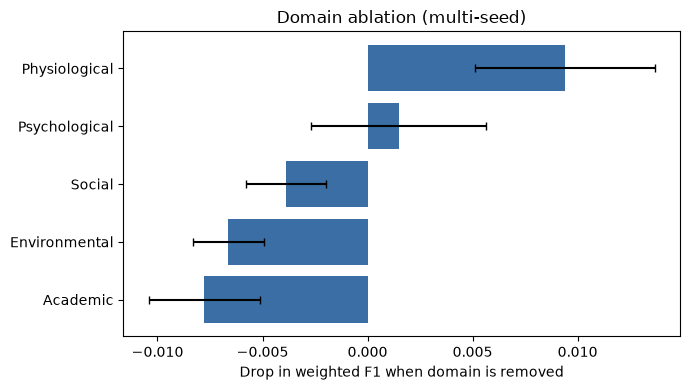

In [11]:
# Step 10: Final results tables and summary plot
summary = comparison[["shap_importance", "drop_one_loss", "only_one_f1", "shap_rank", "drop_rank", "only_rank"]].copy()
summary["mean_loss_multi_seed"] = rob_df.mean()
summary["sd_loss_multi_seed"] = rob_df.std()
summary = summary.sort_values("drop_one_loss", ascending=False)
print(summary.round(4))

baseline.round(4).to_csv("table_baseline.csv")
ablation.round(4).to_csv("table_ablation.csv")
stats_df.round(4).to_csv("table_stats.csv")
summary.round(4).to_csv("table_domain_summary.csv")
whatif_df.round(4).to_csv("table_whatif.csv")

fig, ax = plt.subplots(figsize=(7, 4))
plot_df = summary.sort_values("drop_one_loss")
ax.barh(plot_df.index, plot_df["drop_one_loss"], xerr=plot_df["sd_loss_multi_seed"], color="#3b6ea5", capsize=3)
ax.set_xlabel("Drop in weighted F1 when domain is removed")
ax.set_title("Domain ablation (multi-seed)")
plt.tight_layout()
plt.savefig("domain_ablation.png", dpi=200)
plt.show()